# Wage Determinants and Disparities in the Indian Labour Market
## Exploratory Data Analysis of PLFS Person-Level Data, April–December 2025

**Project area:** Exploratory Data Analysis and Statistical Visualization  
**Primary questions:** How do gender, education, rural–urban location, industry, occupation, and geography relate to earnings? How large are the observed gaps before and after statistical adjustment?

**Data:** Periodic Labour Force Survey (PLFS), Schedule 10.4, final multiplier-posted person-level unit records for Q2–Q4 2025. The analysis uses the supplied `MPER_Q2_Q4_2025.zip`, data layout, state/UT code file, and official field instructions.

> **Interpretation boundary:** Regular salary and casual daily wages are measured on different reference bases and are analysed separately. The CWS person file does not contain written-contract or social-security variables; consequently, regular versus casual employment is **not** labelled as formal versus informal employment. Findings are descriptive associations, not causal effects.

## Contents
1. Setup and data understanding  
2. Data audit, cleaning, and feature construction  
3. Survey-weighted methodology  
4. Overall earnings distributions  
5. Gender and education disparities  
6. Sector, quarter, industry, occupation, and state patterns  
7. Casual daily wage analysis  
8. Multivariable log-earnings models  
9. Observations, interpretation, conclusion, and limitations

## 1. Setup and data understanding

The notebook is self-contained. Place the ZIP, data-layout workbook, and state/UT code workbook beside it, or keep them in a `data` subfolder. No internet connection is required.

In [1]:
%matplotlib inline
from pathlib import Path
import zipfile, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.formula.api as smf

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', context='notebook')

NAVY='#17324D'; TEAL='#2A9D8F'; GOLD='#E9A23B'; CORAL='#D65F5F'; GREY='#6B7280'
GENDER_COLORS={'Male':NAVY,'Female':CORAL}
EDU_ORDER=['No formal schooling','Up to middle','Secondary / higher secondary','Diploma / certificate','Graduate & above']
Q_ORDER=['Apr–Jun 2025','Jul–Sep 2025','Oct–Dec 2025']

def find_file(name, extra=None):
    candidates=[Path.cwd()/name,Path.cwd()/'data'/name]
    if extra: candidates += [Path(extra)/name]
    candidates += [Path('/mnt/agents/upload')/name,Path('/mnt/agents/temp')/name]
    for p in candidates:
        if p.exists(): return p
    raise FileNotFoundError(f'Could not find {name}. Place it beside the notebook or in a data folder.')

ZIP_PATH=find_file('MPER_Q2_Q4_2025.zip')
LAYOUT_PATH=find_file('2_Data_LayoutPLFS_Q2025.xlsx')
STATE_PATH=find_file('4_Indian_States_and_UTs_Code_and_Name.xlsx')
ARTIFACT_DIR=(Path('/mnt/agents/.work/plfs_eda/notebook_artifacts')
              if Path('/mnt/agents/.work').exists() else Path.cwd()/'eda_outputs')
ARTIFACT_DIR.mkdir(parents=True,exist_ok=True)
print('Data archive:',ZIP_PATH)
print('Data layout:',LAYOUT_PATH)
print('Analysis artifacts:',ARTIFACT_DIR)

Data archive: /mnt/agents/upload/MPER_Q2_Q4_2025.zip
Data layout: /mnt/agents/temp/2_Data_LayoutPLFS_Q2025.xlsx
Analysis artifacts: /mnt/agents/.work/plfs_eda/notebook_artifacts


In [2]:
# Verify that the supplied data dictionary contains the expected person-level fields.
layout=pd.read_excel(LAYOUT_PATH,sheet_name='MPER_Q2_Q4_2025')
required=['qtr','month','visit','sec','st','mfsu','sss','ssu','srl','sex','age',
          'gedu_lvl','acws','aind_cws','ocu_cws','ern_reg','ern_self','mult']
missing_in_layout=sorted(set(required)-set(layout['Field_Name']))
assert not missing_in_layout, f'Missing layout fields: {missing_in_layout}'
layout.loc[layout['Field_Name'].isin(required),
           ['Full Name','Field_Name','Field Length','Byte Position (Start)','Byte Position (End)']]

,Full Name,Field_Name,Field Length,Byte Position (Start),Byte Position (End)
2,Quarter,qtr,2,9,10
3,Month,month,2,11,12
4,Visit,visit,2,13,14
5,Sector,sec,1,15,15
6,State/Ut Code,st,2,16,17
14,FSU,mfsu,5,37,41
15,Second Stage Stratum No.,sss,1,42,42
16,Sample Household Number,ssu,2,43,44
17,Person Serial No.,srl,2,45,46
19,Sex,sex,1,48,48


### Measurement choices

| Measure | Source fields | Reference period | Analysis unit |
|---|---|---|---|
| Regular wage/salary earnings | `ern_reg`; CWS 31, 71, 72 | Preceding calendar month | Person-period with positive earnings |
| Casual wage | Daily `ern*`; daily status 41, 42, 51 | Each day of the reference week | Person-day with positive wage |
| Self-employed gross earnings | `ern_self`; CWS 11, 12, 21, 61, 62 | Last 30 days | Person-period with positive gross earnings; contextual only |

The main population is aged 15–59. Survey weights are `MULT / 100`, as specified in the supplied README. Positive-earnings filters identify the paid-worker samples; zeros and structural blanks are not imputed.

## 2. Data audit, cleaning, and feature construction

Only identifiers, demographics, CWS variables, earnings, hours, weights, and daily wage fields are imported. Codes are read as strings where leading zeros matter. The original 108-column source contains 1,696,741 person records.

In [3]:
usecols=['qtr','month','visit','sec','st','dc','mfsu','sss','ssu','srl','sex','age',
         'gedu_lvl','tedu_lvl','tothrs_wrk','acws','aind_cws','ocu_cws','ern_reg','ern_self','mult']
for d in range(1,8):
    usecols += [f'das1{d}',f'hr1{d}',f'ern1{d}',f'das2{d}',f'hr2{d}',f'ern2{d}']
strcols=['qtr','visit','st','gedu_lvl','acws','aind_cws','ocu_cws']
dtype={c:('string' if c in strcols else 'float32') for c in usecols}
with zipfile.ZipFile(ZIP_PATH) as z:
    csv_name=[n for n in z.namelist() if n.lower().endswith('.csv')][0]
    with z.open(csv_name) as f:
        raw=pd.read_csv(f,usecols=usecols,dtype=dtype)

key=['qtr','month','visit','sec','st','mfsu','sss','ssu','srl']
audit=pd.DataFrame({
    'Check':['Person records','Imported fields','Exact duplicate person keys','Non-positive/missing multipliers',
             'Missing gender','Missing age','Missing education','Missing CWS','Minimum age','Maximum age'],
    'Result':[len(raw),len(raw.columns),raw.duplicated(key).sum(),
              (raw['mult'].isna()|(raw['mult']<=0)).sum(),raw['sex'].isna().sum(),
              raw['age'].isna().sum(),raw['gedu_lvl'].isna().sum(),raw['acws'].isna().sum(),
              raw['age'].min(),raw['age'].max()]
})
display(audit)
print('Quarter counts:',raw['qtr'].value_counts().sort_index().to_dict())

,Check,Result
0,Person records,"1,696,741.00"
1,Imported fields,63.00
2,Exact duplicate person keys,0.00
3,Non-positive/missing multipliers,0.00
4,Missing gender,0.00
5,Missing age,0.00
6,Missing education,0.00
7,Missing CWS,0.00
8,Minimum age,0.00
9,Maximum age,117.00


Quarter counts: {'Q2': 570805, 'Q3': 564828, 'Q4': 561108}


In [4]:
# Recode and construct analysis variables.
for c in ['sex','age','sec','st','gedu_lvl','acws','aind_cws','ocu_cws']:
    raw[c+'_n']=pd.to_numeric(raw[c],errors='coerce')
raw['weight']=raw['mult'].astype('float64')/100

edu_map={1:'No formal schooling',2:'No formal schooling',3:'No formal schooling',4:'No formal schooling',
         5:'Up to middle',6:'Up to middle',7:'Up to middle',
         8:'Secondary / higher secondary',10:'Secondary / higher secondary',
         11:'Diploma / certificate',12:'Graduate & above',13:'Graduate & above'}
raw['education']=raw['gedu_lvl_n'].map(edu_map)
raw['gender']=raw['sex_n'].map({1:'Male',2:'Female'})
raw['sector']=raw['sec_n'].map({1:'Rural',2:'Urban'})
raw['age_group']=pd.cut(raw['age_n'],bins=[14,29,44,59],labels=['15–29','30–44','45–59'])
raw['quarter']=raw['qtr'].map({'Q2':'Apr–Jun 2025','Q3':'Jul–Sep 2025','Q4':'Oct–Dec 2025'})

ind=raw['aind_cws_n']
conditions=[ind.between(1,3),ind.between(5,9),ind.between(10,33),ind.between(35,39),
            ind.between(41,43),ind.between(45,47),ind.between(49,53),ind.between(55,63),
            ind.between(64,83),ind.between(84,88),ind.between(90,99)]
conditions=[c.fillna(False).to_numpy(dtype=bool) for c in conditions]
choices=['Agriculture','Mining','Manufacturing','Utilities','Construction','Trade & repair',
         'Transport & storage','Information & other services','Finance, professional & admin services',
         'Public admin, education & health','Other services']
raw['industry_group']=np.select(conditions,choices,default='Other / unclassified')
occ_map={0:'Armed forces',1:'Managers',2:'Professionals',3:'Technicians & associate professionals',
         4:'Clerical support',5:'Service & sales',6:'Skilled agricultural & fishery',
         7:'Craft & related trades',8:'Plant & machine operators',9:'Elementary occupations'}
raw['occupation_group']=np.floor(raw['ocu_cws_n']/100).map(occ_map).fillna('Other / unclassified')

states=pd.read_excel(STATE_PATH,skiprows=1,dtype=str)
states.columns=['st_code','state']
states=states[states['st_code'].str.fullmatch(r'\d+',na=False)].drop_duplicates('st_code')
states['st_n']=pd.to_numeric(states['st_code'])
raw=raw.merge(states[['st_n','state']],left_on='st_n',right_on='st_n',how='left')
raw['state']=raw['state'].fillna('Code '+raw['st'].fillna('missing'))

working=raw[raw['age_n'].between(15,59)].copy()
reg=working[working['acws_n'].isin([31,71,72])&working['ern_reg'].gt(0)&working['weight'].gt(0)].copy()
self_emp=working[working['acws_n'].isin([11,12,21,61,62])&working['ern_self'].gt(0)&working['weight'].gt(0)].copy()
print(f'Working-age records: {len(working):,}')
print(f'Regular earners with positive monthly earnings: {len(reg):,}')
print(f'Self-employed records with positive gross earnings: {len(self_emp):,}')

Working-age records: 1,124,117
Regular earners with positive monthly earnings: 175,840
Self-employed records with positive gross earnings: 240,574


In [5]:
# Expand daily casual activity records, then combine any two activities on the same person-day.
casual_parts=[]
common=['qtr','quarter','month','visit','sec','sector','st','state','mfsu','sss','ssu','srl',
        'sex','gender','age_n','age_group','gedu_lvl_n','education','weight','tothrs_wrk']
for d in range(1,8):
    for a in [1,2]:
        status=working[f'das{a}{d}']; wage=working[f'ern{a}{d}']
        mask=status.isin([41,42,51])&wage.gt(0)&working['weight'].gt(0)
        if mask.any():
            p=working.loc[mask,common].copy()
            p['day']=d; p['daily_wage']=wage[mask].astype('float64')
            p['hours']=working.loc[mask,f'hr{a}{d}']
            casual_parts.append(p)
cas_activity=pd.concat(casual_parts,ignore_index=True)
idcols=['qtr','quarter','month','visit','sec','sector','st','state','mfsu','sss','ssu','srl','day']
firstcols=['gender','sex','age_n','age_group','gedu_lvl_n','education','weight','tothrs_wrk']
cas=cas_activity.groupby(idcols,as_index=False,observed=True).agg(
    {**{c:'first' for c in firstcols},'daily_wage':'sum','hours':'sum'})

flow=pd.DataFrame({
    'Stage':['All source person records','Working age 15–59','Regular earners, positive monthly earnings',
             'Self-employed, positive gross earnings','Casual person-days, positive daily wage'],
    'Records':[len(raw),len(working),len(reg),len(self_emp),len(cas)]
})
display(flow)
print(f'{len(cas_activity)-len(cas):,} additional activity records were consolidated into same-day wages.')
# Release the largest intermediate frames before modelling.
del raw, working, cas_activity, casual_parts

,Stage,Records
0,All source person records,1696741
1,Working age 15–59,1124117
2,"Regular earners, positive monthly earnings",175840
3,"Self-employed, positive gross earnings",240574
4,"Casual person-days, positive daily wage",511561


206 additional activity records were consolidated into same-day wages.


**Cleaning interpretation.** No exact duplicate person keys or missing key demographic/CWS fields were found. Earnings blanks and zeros are largely structural because the relevant question depends on activity status; they are not treated as missing at random. Extreme positive values are retained. Weighted medians, percentile ranges, and log earnings reduce the influence of skewness without silently deleting genuine high earners.

## 3. Survey-weighted methodology

For values \(x_i\) and final weights \(w_i\), the weighted mean is \(\sum w_i x_i / \sum w_i\). Weighted quantiles use the centered cumulative weight distribution. All pooled estimates combine three quarterly person-period samples; weighted totals are therefore not counts of unique individuals.

In [6]:
def wquant(x,w,q):
    x=np.asarray(x,dtype=float); w=np.asarray(w,dtype=float)
    ok=np.isfinite(x)&np.isfinite(w)&(w>0)
    x=x[ok]; w=w[ok]
    order=np.argsort(x); x=x[order]; w=w[order]
    centered=np.cumsum(w)-0.5*w
    return float(np.interp(q*w.sum(),centered,x))

def weighted_stats(g,value):
    x=g[value].astype(float); w=g['weight'].astype(float)
    return pd.Series({'n':len(g),'weighted_total':w.sum(),
                      'mean':np.average(x,weights=w),'p25':wquant(x,w,.25),
                      'median':wquant(x,w,.5),'p75':wquant(x,w,.75),'p90':wquant(x,w,.9)})

def grouped_stats(df,groups,value):
    return (df.groupby(groups,observed=True,dropna=False)
              .apply(lambda g:weighted_stats(g,value),include_groups=False).reset_index())

def savefig(fig,name):
    fig.savefig(ARTIFACT_DIR/name,dpi=180,bbox_inches='tight',facecolor='white')
    plt.show()

def gender_gap(table,value='median'):
    p=table.pivot(index=table.columns[0],columns='gender',values=value)
    return (p['Male']-p['Female'])/p['Male']*100

## 4. Overall earnings distributions

The monthly and daily metrics are intentionally shown in separate panels. Self-employed gross earnings are summarised for context but are not equated with wages.

,Measure,n,mean,p25,median,p75,p90
0,Regular monthly earnings,"175,840.00","22,959.31","10,000.00","15,000.00","26,000.00","48,500.00"
1,Casual daily wage,"511,561.00",454.87,350.00,400.00,500.00,700.00
2,Self-employed gross earnings (30 days),"240,574.00","15,103.07","6,500.00","12,000.00","18,560.00","28,650.00"


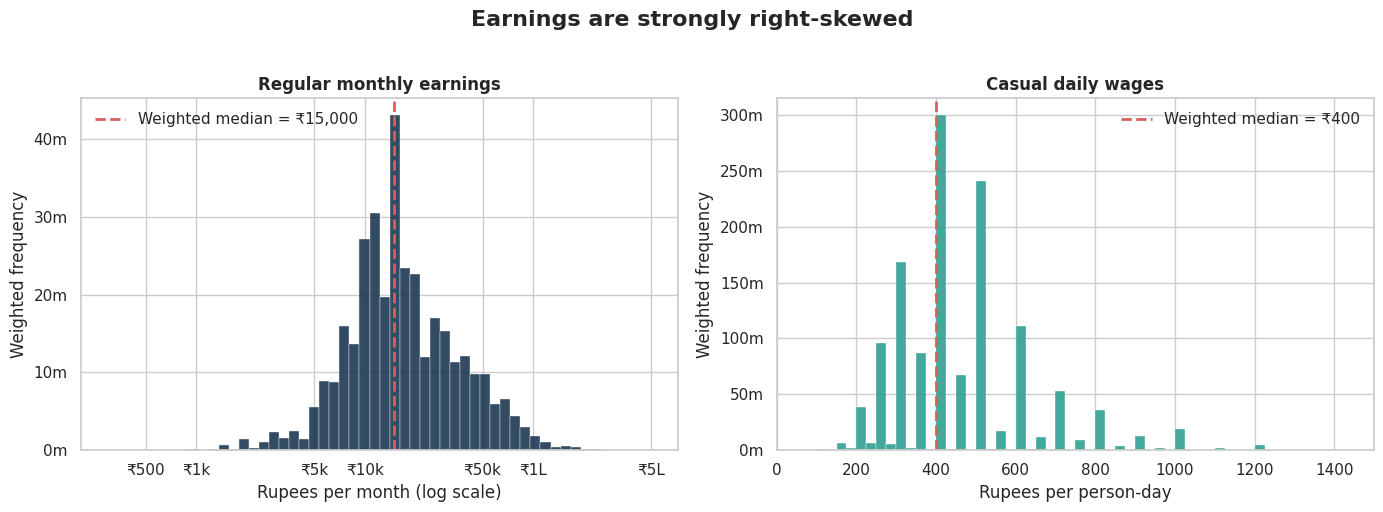

In [7]:
overall_reg=weighted_stats(reg,'ern_reg')
overall_cas=weighted_stats(cas,'daily_wage')
overall_self=weighted_stats(self_emp,'ern_self')
summary=pd.DataFrame([
    {'Measure':'Regular monthly earnings',**overall_reg.to_dict()},
    {'Measure':'Casual daily wage',**overall_cas.to_dict()},
    {'Measure':'Self-employed gross earnings (30 days)',**overall_self.to_dict()}
])
display(summary[['Measure','n','mean','p25','median','p75','p90']])

fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,data,value,bins,color,title,xlabel in [
    (axes[0],reg,'ern_reg',np.logspace(np.log10(300),np.log10(500000),55),NAVY,
     'Regular monthly earnings','Rupees per month (log scale)'),
    (axes[1],cas,'daily_wage',np.arange(0,1550,25),TEAL,
     'Casual daily wages','Rupees per person-day')]:
    ax.hist(data[value],bins=bins,weights=data['weight'],color=color,alpha=.88,edgecolor='white',linewidth=.3)
    med=wquant(data[value],data['weight'],.5)
    ax.axvline(med,color=CORAL,ls='--',lw=2,label=f'Weighted median = ₹{med:,.0f}')
    ax.set_title(title,fontweight='bold'); ax.set_xlabel(xlabel); ax.set_ylabel('Weighted frequency')
    ax.legend(frameon=False); ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x,pos:f'{x/1e6:.0f}m'))
axes[0].set_xscale('log'); axes[0].set_xticks([500,1000,5000,10000,50000,100000,500000])
axes[0].set_xticklabels(['₹500','₹1k','₹5k','₹10k','₹50k','₹1L','₹5L'])
axes[1].set_xlim(0,1500)
fig.suptitle('Earnings are strongly right-skewed',fontsize=16,fontweight='bold',y=1.02)
fig.tight_layout(); savefig(fig,'01_earnings_distributions.png')

In [8]:
print(f"Regular monthly earnings: weighted mean ₹{overall_reg['mean']:,.0f}; median ₹{overall_reg['median']:,.0f}; "
      f"middle 50% ₹{overall_reg['p25']:,.0f}–₹{overall_reg['p75']:,.0f}.")
print(f"Casual daily wage: weighted mean ₹{overall_cas['mean']:,.0f}; median ₹{overall_cas['median']:,.0f}; "
      f"middle 50% ₹{overall_cas['p25']:,.0f}–₹{overall_cas['p75']:,.0f}.")
print(f"The regular-earnings mean is {overall_reg['mean']/overall_reg['median']:.2f}× its median, confirming right-skew.")

Regular monthly earnings: weighted mean ₹22,959; median ₹15,000; middle 50% ₹10,000–₹26,000.
Casual daily wage: weighted mean ₹455; median ₹400; middle 50% ₹350–₹500.
The regular-earnings mean is 1.53× its median, confirming right-skew.


## 5. Gender and education disparities

The **median gender gap** is calculated as \((M-F)/M 	imes 100\). It is a descriptive gap, not proof of discrimination: differences in occupation, hours, experience, industry, and location can contribute.

,gender,n,mean,p25,median,p75,p90
0,Female,"45,179.00","18,532.70","7,000.00","10,500.00","20,000.00","45,000.00"
1,Male,"130,657.00","24,512.55","12,000.00","17,000.00","28,000.00","50,000.00"


Overall median gender gap: 38.2%


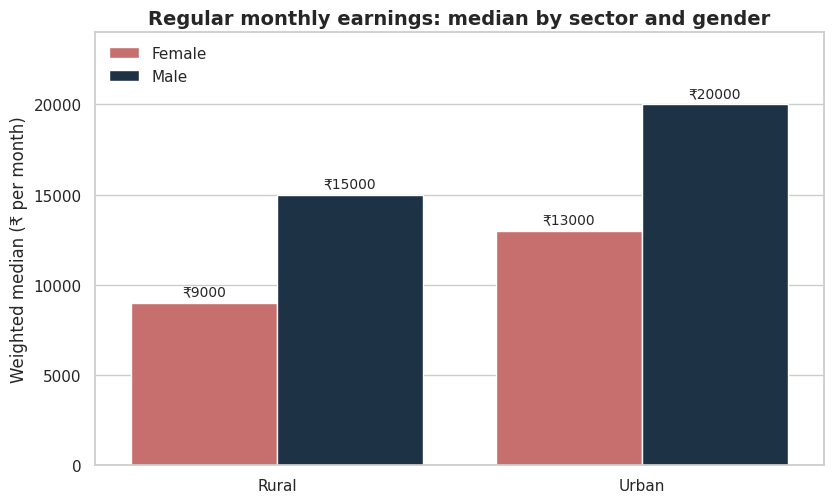

In [9]:
reg_gender=grouped_stats(reg.dropna(subset=['gender']),['gender'],'ern_reg')
reg_sector_gender=grouped_stats(reg.dropna(subset=['gender']),['sector','gender'],'ern_reg')
display(reg_gender[['gender','n','mean','p25','median','p75','p90']])
raw_median_gap=(reg_gender.set_index('gender').loc['Male','median']-
                reg_gender.set_index('gender').loc['Female','median'])/reg_gender.set_index('gender').loc['Male','median']*100
print(f'Overall median gender gap: {raw_median_gap:.1f}%')

fig,ax=plt.subplots(figsize=(8.5,5.2))
plot=reg_sector_gender.dropna(subset=['gender'])
sns.barplot(data=plot,x='sector',y='median',hue='gender',palette=GENDER_COLORS,ax=ax)
for container in ax.containers: ax.bar_label(container,fmt='₹%.0f',padding=3,fontsize=10)
ax.set_title('Regular monthly earnings: median by sector and gender',fontweight='bold',fontsize=14)
ax.set_xlabel('');ax.set_ylabel('Weighted median (₹ per month)');ax.set_ylim(0,24000)
ax.legend(title='',frameon=False,loc='upper left');fig.tight_layout()
savefig(fig,'02_gender_sector.png')

,education,gender,n,mean,p25,median,p75,p90
4,No formal schooling,Female,"4,007.00","7,175.86","4,500.00","6,762.23","9,000.00","12,000.00"
5,No formal schooling,Male,"4,026.00","13,385.76","9,000.00","12,000.00","15,000.00","20,000.00"
8,Up to middle,Female,"9,602.00","8,797.22","5,500.00","8,000.00","10,500.00","15,000.00"
9,Up to middle,Male,"29,741.00","15,029.43","10,000.00","14,000.00","18,000.00","22,000.00"
6,Secondary / higher secondary,Female,"10,436.00","11,988.59","7,000.00","10,000.00","13,659.15","20,000.00"
7,Secondary / higher secondary,Male,"43,914.00","18,812.25","12,000.00","15,000.00","21,000.00","32,000.00"
0,Diploma / certificate,Female,"1,466.00","22,442.41","10,000.00","15,000.00","25,000.00","50,000.00"
1,Diploma / certificate,Male,"6,036.00","26,533.56","15,000.00","20,150.00","32,000.00","50,000.00"
2,Graduate & above,Female,"19,668.00","31,285.14","12,478.15","24,890.50","42,000.00","65,000.00"
3,Graduate & above,Male,"46,940.00","38,450.28","18,000.00","30,000.00","50,000.00","72,500.00"


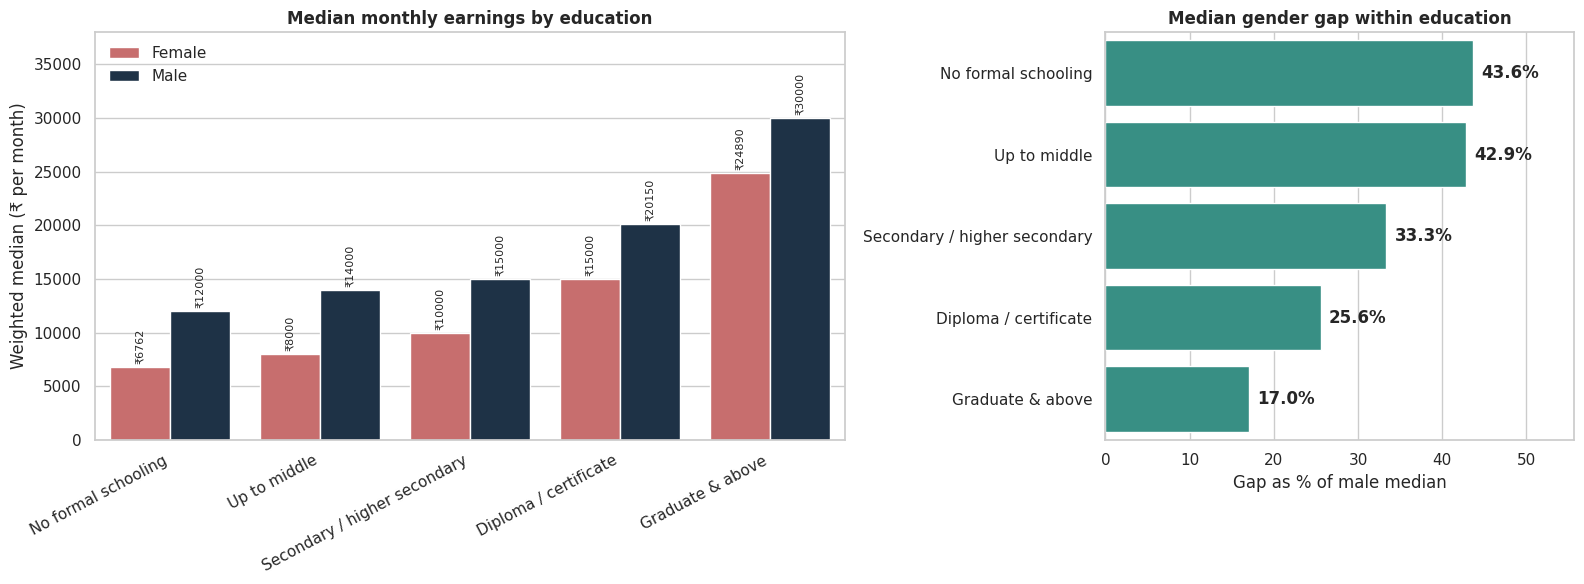

In [10]:
reg_edu_gender=grouped_stats(reg.dropna(subset=['gender','education']),['education','gender'],'ern_reg')
reg_edu_gender['education']=pd.Categorical(reg_edu_gender['education'],EDU_ORDER,ordered=True)
reg_edu_gender=reg_edu_gender.sort_values(['education','gender'])
display(reg_edu_gender[['education','gender','n','mean','p25','median','p75','p90']])

fig,axes=plt.subplots(1,2,figsize=(16,6),gridspec_kw={'width_ratios':[1.6,1]})
sns.barplot(data=reg_edu_gender,x='education',y='median',hue='gender',palette=GENDER_COLORS,ax=axes[0])
for container in axes[0].containers: axes[0].bar_label(container,fmt='₹%.0f',padding=2,fontsize=8,rotation=90)
axes[0].set_title('Median monthly earnings by education',fontweight='bold')
axes[0].set_xlabel('');axes[0].set_ylabel('Weighted median (₹ per month)')
axes[0].tick_params(axis='x',rotation=28);axes[0].legend(title='',frameon=False)
axes[0].set_ylim(0,38000)
for label in axes[0].get_xticklabels(): label.set_ha('right')

gaps=gender_gap(reg_edu_gender).reindex(EDU_ORDER)
sns.barplot(x=gaps.values,y=gaps.index,color=TEAL,ax=axes[1])
for i,v in enumerate(gaps.values): axes[1].text(v+1,i,f'{v:.1f}%',va='center',fontweight='bold')
axes[1].set_title('Median gender gap within education',fontweight='bold')
axes[1].set_xlabel('Gap as % of male median');axes[1].set_ylabel('');axes[1].set_xlim(0,max(gaps.values)+12)
fig.tight_layout();savefig(fig,'03_education_gender.png')

In [11]:
grad_gap=gender_gap(reg_edu_gender).loc['Graduate & above']
noedu_gap=gender_gap(reg_edu_gender).loc['No formal schooling']
print(f'The median gender gap is {noedu_gap:.1f}% among workers with no formal schooling and '
      f'{grad_gap:.1f}% among graduates and above.')
print('Education is associated with higher earnings for both genders, but the gap does not disappear at any level.')

The median gender gap is 43.6% among workers with no formal schooling and 17.0% among graduates and above.
Education is associated with higher earnings for both genders, but the gap does not disappear at any level.


## 6. Sector, quarter, industry, occupation, and state patterns

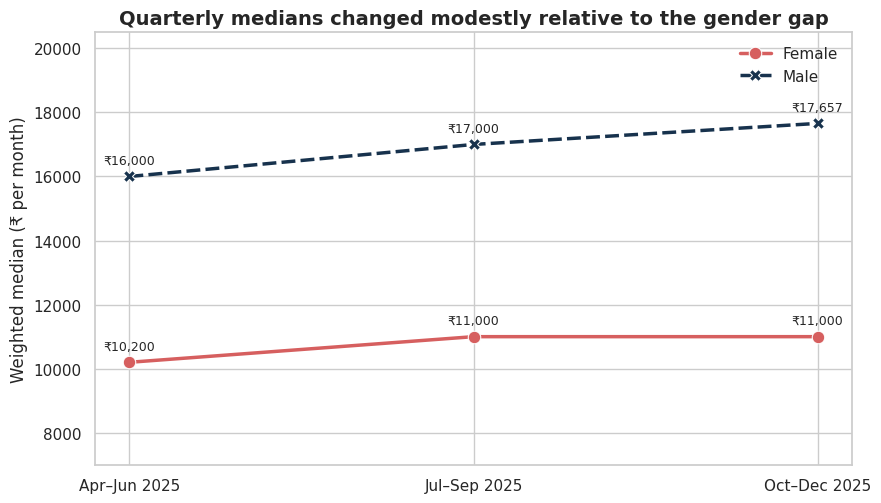

In [12]:
reg_quarter_gender=grouped_stats(reg.dropna(subset=['gender']),['quarter','gender'],'ern_reg')
reg_quarter_gender['quarter']=pd.Categorical(reg_quarter_gender['quarter'],Q_ORDER,ordered=True)
fig,ax=plt.subplots(figsize=(9,5.2))
sns.lineplot(data=reg_quarter_gender,x='quarter',y='median',hue='gender',style='gender',
             markers=True,markersize=9,lw=2.5,palette=GENDER_COLORS,ax=ax)
for _,r in reg_quarter_gender.iterrows():
    ax.annotate(f"₹{r['median']:,.0f}",(r['quarter'],r['median']),textcoords='offset points',xytext=(0,9),ha='center',fontsize=9)
ax.set_title('Quarterly medians changed modestly relative to the gender gap',fontweight='bold',fontsize=14)
ax.set_xlabel('');ax.set_ylabel('Weighted median (₹ per month)');ax.set_ylim(7000,20500)
ax.legend(title='',frameon=False);fig.tight_layout();savefig(fig,'04_quarter_trend.png')

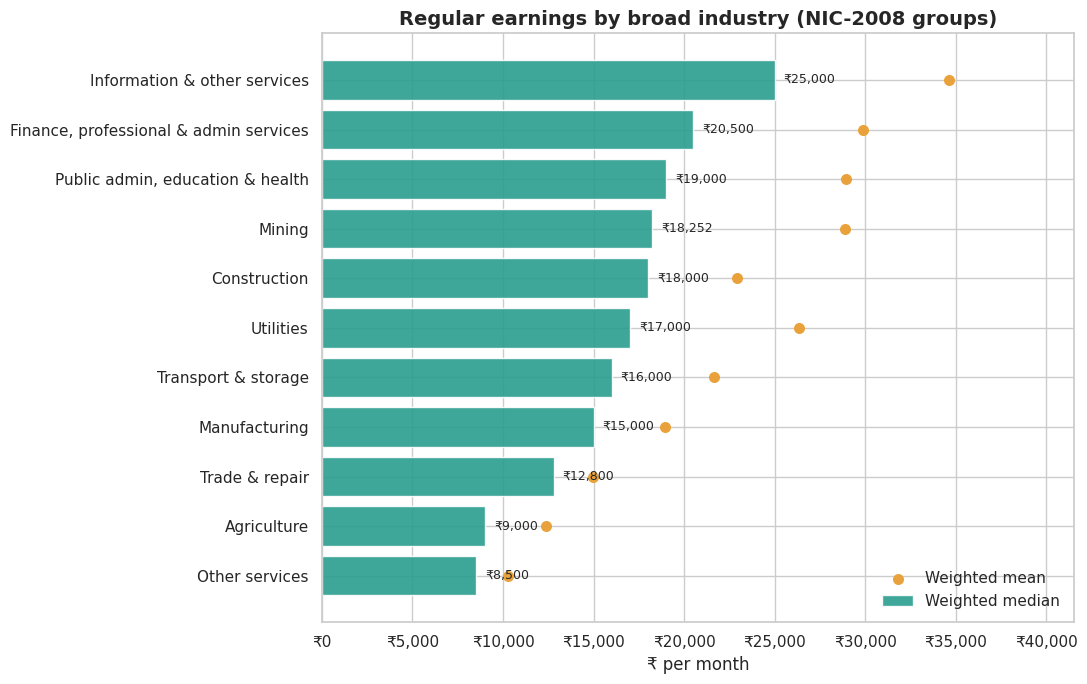

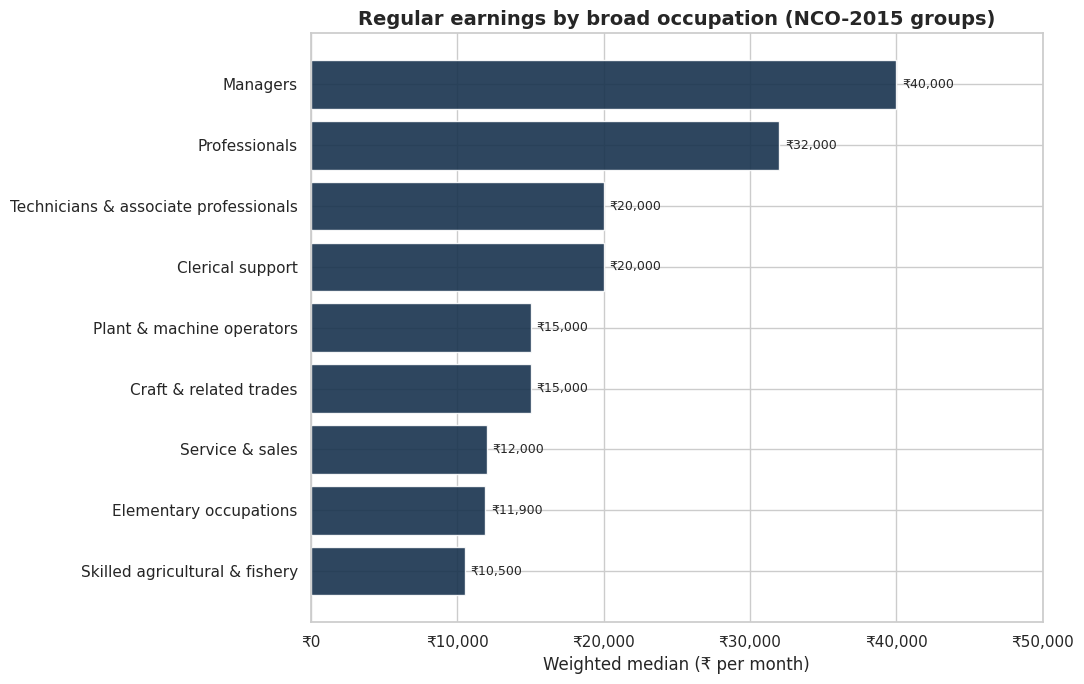

In [13]:
reg_industry=grouped_stats(reg,['industry_group'],'ern_reg').sort_values('median')
reg_occupation=grouped_stats(reg,['occupation_group'],'ern_reg').sort_values('median')

fig,ax=plt.subplots(figsize=(11,7))
y=np.arange(len(reg_industry))
ax.barh(y,reg_industry['median'],color=TEAL,alpha=.9,label='Weighted median')
ax.scatter(reg_industry['mean'],y,color=GOLD,s=48,zorder=3,label='Weighted mean')
ax.set_yticks(y,reg_industry['industry_group']);ax.set_xlabel('₹ per month')
ax.set_title('Regular earnings by broad industry (NIC-2008 groups)',fontweight='bold',fontsize=14)
ax.legend(frameon=False,loc='lower right');ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('₹{x:,.0f}'))
for i,v in enumerate(reg_industry['median']): ax.text(v+500,i,f'₹{v:,.0f}',va='center',fontsize=9)
ax.set_xlim(0,max(reg_industry['mean'])*1.2);fig.tight_layout();savefig(fig,'05_industry.png')

fig,ax=plt.subplots(figsize=(11,7))
y=np.arange(len(reg_occupation))
ax.barh(y,reg_occupation['median'],color=NAVY,alpha=.9)
ax.set_yticks(y,reg_occupation['occupation_group']);ax.set_xlabel('Weighted median (₹ per month)')
ax.set_title('Regular earnings by broad occupation (NCO-2015 groups)',fontweight='bold',fontsize=14)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('₹{x:,.0f}'))
for i,v in enumerate(reg_occupation['median']): ax.text(v+400,i,f'₹{v:,.0f}',va='center',fontsize=9)
ax.set_xlim(0,reg_occupation['median'].max()*1.25);fig.tight_layout();savefig(fig,'06_occupation.png')

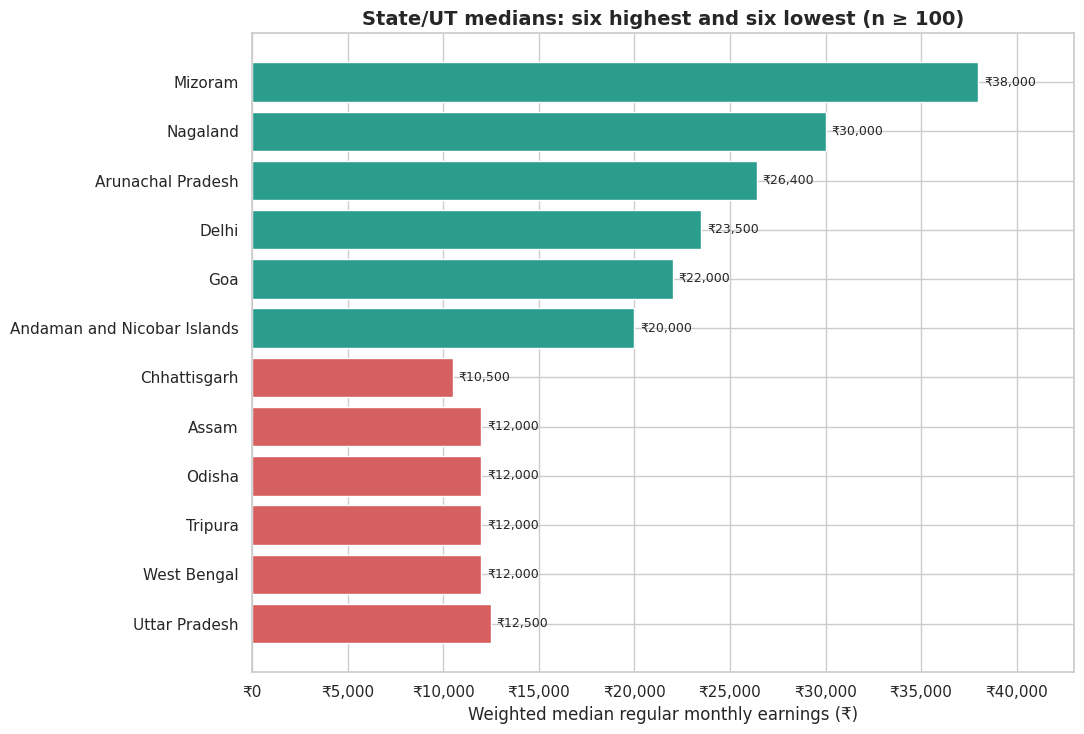

Highest three: [{'state': 'Mizoram', 'median': 38000.0, 'n': 1086.0}, {'state': 'Nagaland', 'median': 30000.0, 'n': 1077.0}, {'state': 'Arunachal Pradesh', 'median': 26400.0, 'n': 1493.0}]
Lowest three: [{'state': 'Odisha', 'median': 12000.0, 'n': 5634.0}, {'state': 'West Bengal', 'median': 12000.0, 'n': 8459.0}, {'state': 'Chhattisgarh', 'median': 10500.0, 'n': 6462.0}]
These raw rankings also reflect differences in education, occupation, industry, and rural–urban composition.


In [14]:
reg_state=grouped_stats(reg,['state'],'ern_reg')
# Reliability screen for descriptive ranking; excluded small samples remain in national estimates.
state_eligible=reg_state[reg_state['n']>=100].sort_values('median',ascending=False)
state_extremes=pd.concat([state_eligible.head(6),state_eligible.tail(6).sort_values('median')])
fig,ax=plt.subplots(figsize=(11,7.5))
colors=[TEAL]*6+[CORAL]*6
ax.barh(state_extremes['state'][::-1],state_extremes['median'][::-1],color=colors[::-1])
for i,v in enumerate(state_extremes['median'][::-1]): ax.text(v+300,i,f'₹{v:,.0f}',va='center',fontsize=9)
ax.set_title('State/UT medians: six highest and six lowest (n ≥ 100)',fontweight='bold',fontsize=14)
ax.set_xlabel('Weighted median regular monthly earnings (₹)')
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('₹{x:,.0f}'));ax.set_xlim(0,43000)
fig.tight_layout();savefig(fig,'07_states.png')
print('Highest three:',state_eligible[['state','median','n']].head(3).to_dict('records'))
print('Lowest three:',state_eligible[['state','median','n']].tail(3).to_dict('records'))
print('These raw rankings also reflect differences in education, occupation, industry, and rural–urban composition.')

## 7. Casual daily wage analysis

Multiple casual activities performed by the same person on the same day are summed before calculating person-day statistics. The weighted unit is a paid person-day, not a unique worker.

,sector,gender,n,mean,p25,median,p75,p90
0,Rural,Female,"90,203.00",321.00,250.00,300.00,400.00,450.00
1,Rural,Male,"297,190.00",469.88,400.00,450.00,500.00,700.00
2,Urban,Female,"16,216.00",377.95,300.00,350.00,450.00,600.00
3,Urban,Male,"107,940.00",585.22,400.00,500.00,700.00,900.00


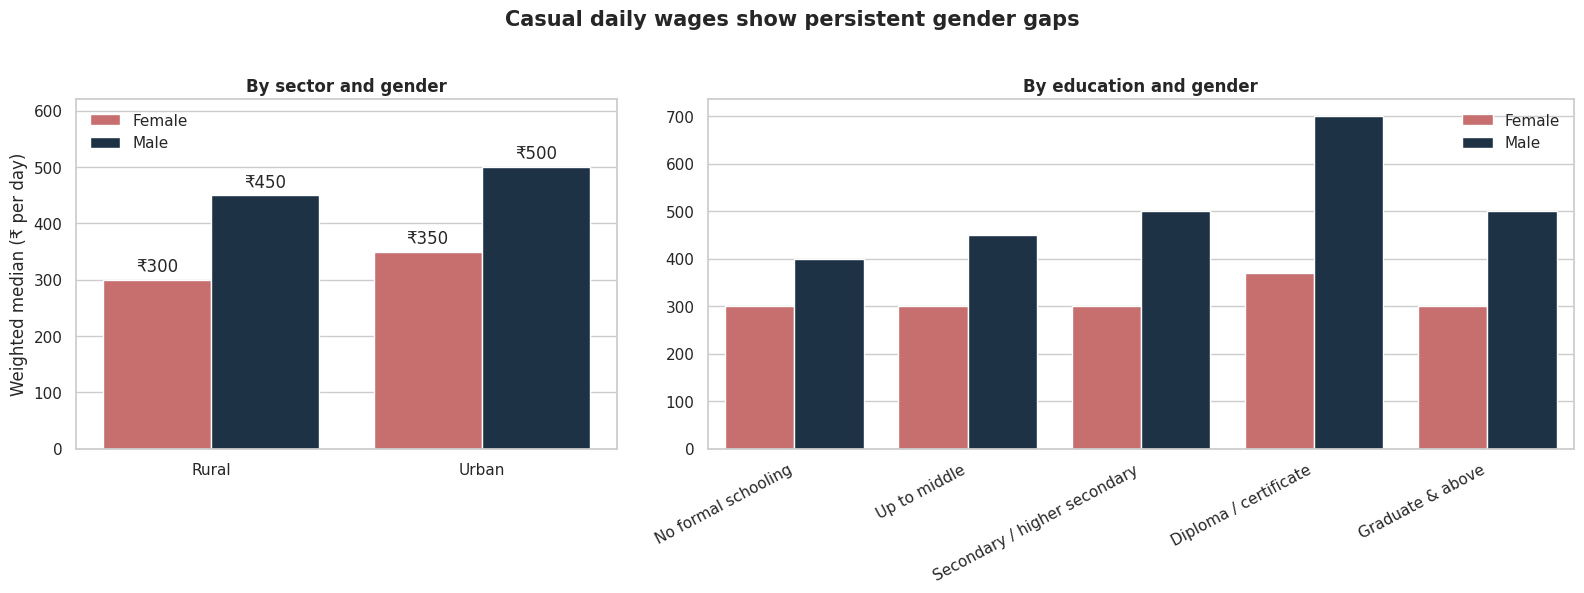

Overall casual median daily wage: male ₹450; female ₹300; gap 33.3%.


In [15]:
cas_sector_gender=grouped_stats(cas.dropna(subset=['gender']),['sector','gender'],'daily_wage')
cas_edu_gender=grouped_stats(cas.dropna(subset=['gender','education']),['education','gender'],'daily_wage')
cas_edu_gender['education']=pd.Categorical(cas_edu_gender['education'],EDU_ORDER,ordered=True)
display(cas_sector_gender[['sector','gender','n','mean','p25','median','p75','p90']])

fig,axes=plt.subplots(1,2,figsize=(16,5.8),gridspec_kw={'width_ratios':[1,1.6]})
sns.barplot(data=cas_sector_gender,x='sector',y='median',hue='gender',palette=GENDER_COLORS,ax=axes[0])
for c in axes[0].containers: axes[0].bar_label(c,fmt='₹%.0f',padding=3)
axes[0].set_title('By sector and gender',fontweight='bold');axes[0].set_xlabel('')
axes[0].set_ylabel('Weighted median (₹ per day)');axes[0].legend(title='',frameon=False);axes[0].set_ylim(0,620)
sns.barplot(data=cas_edu_gender,x='education',y='median',hue='gender',palette=GENDER_COLORS,ax=axes[1])
axes[1].set_title('By education and gender',fontweight='bold');axes[1].set_xlabel('');axes[1].set_ylabel('')
axes[1].tick_params(axis='x',rotation=28);axes[1].legend(title='',frameon=False)
for label in axes[1].get_xticklabels(): label.set_ha('right')
fig.suptitle('Casual daily wages show persistent gender gaps',fontsize=15,fontweight='bold',y=1.02)
fig.tight_layout();savefig(fig,'08_casual_wages.png')

cas_gender=grouped_stats(cas.dropna(subset=['gender']),['gender'],'daily_wage')
cas_gap=(cas_gender.set_index('gender').loc['Male','median']-cas_gender.set_index('gender').loc['Female','median'])/cas_gender.set_index('gender').loc['Male','median']*100
print(f'Overall casual median daily wage: male ₹{cas_gender.set_index("gender").loc["Male","median"]:,.0f}; '
      f'female ₹{cas_gender.set_index("gender").loc["Female","median"]:,.0f}; gap {cas_gap:.1f}%.')

## 8. Multivariable log-earnings models

A survey-weighted least-squares model extends the EDA by estimating associations with log monthly regular earnings. Standard errors are clustered by FSU. Three specifications separate the raw log gap from adjusted associations:

- **M1:** gender only.
- **M2:** adds education, age and age squared, sector, and weekly hours.
- **M3:** adds quarter, broad industry, broad occupation, and state/UT fixed effects.

Coefficients are converted to percentage associations using \(100(e^eta-1)\). These are not causal returns: the survey is observational, repeated panel observations may remain, and cluster-robust errors do not reproduce the full PLFS design-based variance estimator.

In [16]:
model_df=reg.dropna(subset=['gender','education','sector','quarter','industry_group',
                            'occupation_group','state','age_n','tothrs_wrk','ern_reg','weight']).copy()
model_df=model_df[(model_df['weight']>0)&(model_df['ern_reg']>0)&(model_df['tothrs_wrk']>=0)]
model_df['log_wage']=np.log(model_df['ern_reg'].astype(float))
model_df['age_sq']=model_df['age_n'].astype(float)**2
model_df['w']=model_df['weight']/model_df['weight'].mean()
model_df['cluster']=(model_df['st'].astype(str)+'_'+model_df['sec'].astype(str)+'_'+
                     model_df['mfsu'].astype(int).astype(str))
base="C(gender, Treatment(reference='Female')) + C(education, Treatment(reference='No formal schooling')) + age_n + age_sq + C(sector, Treatment(reference='Rural')) + tothrs_wrk"
full=base+" + C(quarter) + C(industry_group, Treatment(reference='Agriculture')) + C(occupation_group, Treatment(reference='Elementary occupations')) + C(state)"
formulas={'M1: raw':"log_wage ~ C(gender, Treatment(reference='Female'))",
          'M2: demographics':'log_wage ~ '+base,
          'M3: fully adjusted':'log_wage ~ '+full}
fits={};coef_rows=[];model_summary=[]
for name,formula in formulas.items():
    print('Fitting',name)
    fit=smf.wls(formula,data=model_df,weights=model_df['w']).fit(
        cov_type='cluster',cov_kwds={'groups':model_df['cluster']})
    fits[name]=fit
    model_summary.append({'Model':name,'n':int(fit.nobs),'R-squared':fit.rsquared,
                          'FSU clusters':model_df['cluster'].nunique()})
    for term in fit.params.index:
        if term=='Intercept': continue
        beta=fit.params[term];se=fit.bse[term]
        coef_rows.append({'Model':name,'Term':term,'beta':beta,'SE':se,'p_value':fit.pvalues[term],
                          'percent':100*np.expm1(beta),
                          'ci_low':100*np.expm1(beta-1.96*se),'ci_high':100*np.expm1(beta+1.96*se)})
coef_table=pd.DataFrame(coef_rows)
model_summary=pd.DataFrame(model_summary)
display(model_summary)
male_term="C(gender, Treatment(reference='Female'))[T.Male]"
display(coef_table[coef_table['Term'].eq(male_term)][['Model','beta','SE','percent','ci_low','ci_high','p_value']])

Fitting M1: raw


Fitting M2: demographics


Fitting M3: fully adjusted


,Model,n,R-squared,FSU clusters
0,M1: raw,175836,0.07,20735
1,M2: demographics,175836,0.42,20735
2,M3: fully adjusted,175836,0.52,20735


,Model,beta,SE,percent,ci_low,ci_high,p_value
0,M1: raw,0.44,0.01,55.87,52.76,59.05,0.00
1,M2: demographics,0.45,0.01,56.65,54.36,58.98,0.00
10,M3: fully adjusted,0.42,0.01,52.75,50.45,55.07,0.00


,label,percent,ci_low,ci_high,p_value
15,Urban vs rural,22.11,20.20,24.06,0.00
12,Graduate+ vs no formal schooling,106.09,100.16,112.19,0.00
11,Diploma vs no formal schooling,70.34,64.21,76.69,0.00
13,Secondary/HS vs no formal schooling,37.90,34.35,41.54,0.00
14,Up to middle vs no formal schooling,17.76,14.77,20.82,0.00
10,Male vs female,52.75,50.45,55.07,0.00


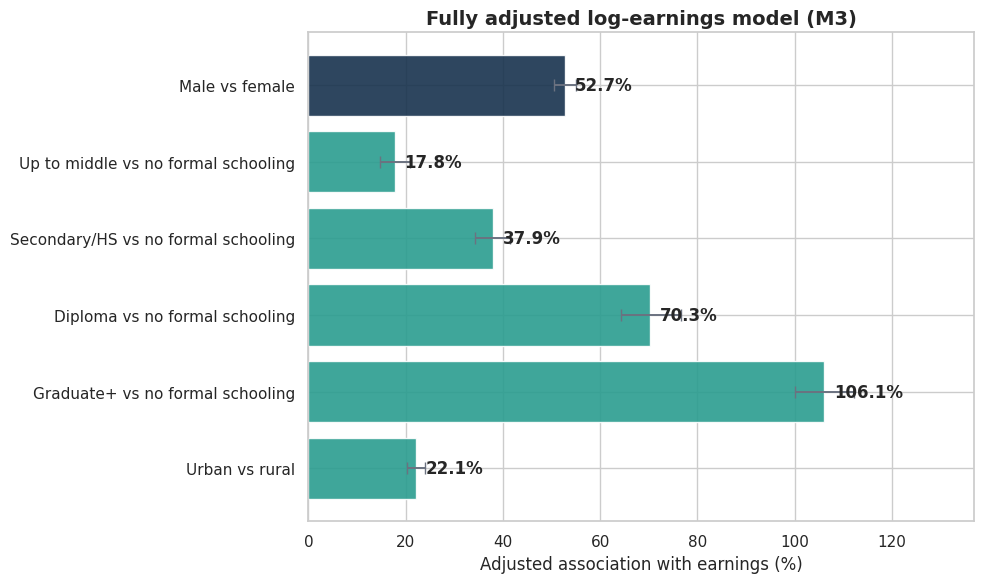

In [17]:
term_labels={
 male_term:'Male vs female',
 "C(education, Treatment(reference='No formal schooling'))[T.Up to middle]":'Up to middle vs no formal schooling',
 "C(education, Treatment(reference='No formal schooling'))[T.Secondary / higher secondary]":'Secondary/HS vs no formal schooling',
 "C(education, Treatment(reference='No formal schooling'))[T.Diploma / certificate]":'Diploma vs no formal schooling',
 "C(education, Treatment(reference='No formal schooling'))[T.Graduate & above]":'Graduate+ vs no formal schooling',
 "C(sector, Treatment(reference='Rural'))[T.Urban]":'Urban vs rural'}
key_coefs=(coef_table[(coef_table['Model']=='M3: fully adjusted')&coef_table['Term'].isin(term_labels)]
           .copy())
key_coefs['label']=key_coefs['Term'].map(term_labels)
key_coefs['order']=key_coefs['Term'].map({k:i for i,k in enumerate(term_labels)})
key_coefs=key_coefs.sort_values('order',ascending=False)
display(key_coefs[['label','percent','ci_low','ci_high','p_value']])

fig,ax=plt.subplots(figsize=(10,6))
y=np.arange(len(key_coefs))
ax.barh(y,key_coefs['percent'],color=[NAVY if 'Male' in x else TEAL for x in key_coefs['label']],alpha=.9)
ax.errorbar(key_coefs['percent'],y,
            xerr=[key_coefs['percent']-key_coefs['ci_low'],key_coefs['ci_high']-key_coefs['percent']],
            fmt='none',ecolor=GREY,capsize=4,lw=1.4)
ax.set_yticks(y,key_coefs['label']);ax.set_xlabel('Adjusted association with earnings (%)')
ax.set_title('Fully adjusted log-earnings model (M3)',fontweight='bold',fontsize=14)
for i,v in enumerate(key_coefs['percent']): ax.text(v+2,i,f'{v:.1f}%',va='center',fontweight='bold')
ax.set_xlim(0,key_coefs['ci_high'].max()*1.22);fig.tight_layout();savefig(fig,'09_regression.png')

In [18]:
male_raw=coef_table.query("Model == 'M1: raw' and Term == @male_term")['percent'].iloc[0]
male_adjusted=coef_table.query("Model == 'M3: fully adjusted' and Term == @male_term")['percent'].iloc[0]
grad_premium=key_coefs.loc[key_coefs['label'].eq('Graduate+ vs no formal schooling'),'percent'].iloc[0]
urban_premium=key_coefs.loc[key_coefs['label'].eq('Urban vs rural'),'percent'].iloc[0]
print(f'Male association in geometric-mean earnings: {male_raw:.1f}% raw and {male_adjusted:.1f}% fully adjusted.')
print(f'Adjusted graduate+ association vs no formal schooling: {grad_premium:.1f}%.')
print(f'Adjusted urban association vs rural: {urban_premium:.1f}%.')
print('Note: geometric-mean log-model gaps need not equal the median gaps shown earlier.')

Male association in geometric-mean earnings: 55.9% raw and 52.7% fully adjusted.
Adjusted graduate+ association vs no formal schooling: 106.1%.
Adjusted urban association vs rural: 22.1%.
Note: geometric-mean log-model gaps need not equal the median gaps shown earlier.


## 9. Observations, interpretation, and conclusion

### Observations
1. Regular monthly earnings have a weighted median of **₹15,000** and mean of **₹22,959**; the middle 50% lies between **₹10,000 and ₹26,000**.
2. The male and female medians are **₹17,000 and ₹10,500**, respectively—a raw median gender gap of **38.2%**.
3. Earnings rise monotonically across the five education groups. The median gender gap is smaller among graduates and above (**17.0%**) than among those without formal schooling (**43.6%**), but it remains present.
4. Urban medians exceed rural medians for both genders. Male medians are ₹20,000 versus ₹15,000; female medians are ₹13,000 versus ₹9,000.
5. Industry and occupation gradients are substantial. Information and other services has the highest broad-industry median (**₹25,000**), while other services and agriculture are at the lower end.
6. Casual daily wages also show a large gap: male median **₹450** and female median **₹300**, a **33.3%** difference.
7. In the fully adjusted log model, the male coefficient corresponds to **52.7%** higher geometric-mean earnings; graduate-and-above and urban coefficients correspond to **106.1%** and **22.1%**, respectively, relative to their stated reference groups.

### Interpretation
Gender, education, location, industry, occupation, and state are all salient dimensions of earnings inequality. Education is strongly associated with higher earnings and a smaller median gender gap, yet the persistence of adjusted gender associations means that observable job and demographic characteristics do not fully account for the disparity. The right-skew and large industry/state variation show why a single national average is insufficient for describing typical workers.

### Conclusion
The PLFS data reveal a segmented earnings structure rather than one uniform labour market. Policy and further research should combine educational expansion with attention to occupational access, job quality, regional differences, and gender-specific barriers. The analysis supports targeted investigation of within-occupation and within-industry wage setting, hours, experience, and employment conditions.

### Limitations and next steps
- Associations are descriptive and not causal; longitudinal experience, actual hours in the earnings reference month, and household-care constraints are not fully controlled.
- Regular earnings and casual wages use different reference periods and units; they must not be directly subtracted or averaged together.
- Regular versus casual status is not a direct formal/informal classification. Contract and social-security variables are needed for that analysis.
- State rankings are composition-sensitive, and small-sample states/UTs are screened out of the ranking chart only.
- Design-based replicate variance estimation and pooled cross-sectional or decomposition methods are natural extensions.

### Reproducibility
All estimates are generated directly from the supplied archive using final multipliers. Figures and machine-readable summary tables are saved to the analysis-artifacts directory when the notebook runs.

In [19]:
# Save key outputs for auditing and report generation.
def json_default(o):
    if isinstance(o,(np.integer,)): return int(o)
    if isinstance(o,(np.floating,)): return None if not np.isfinite(o) else float(o)
    if isinstance(o,(np.ndarray,)): return o.tolist()
    if pd.isna(o): return None
    return str(o)

tables={
 'reg_gender':reg_gender,'reg_sector_gender':reg_sector_gender,'reg_edu_gender':reg_edu_gender,
 'reg_quarter_gender':reg_quarter_gender,'reg_industry':reg_industry,'reg_occupation':reg_occupation,
 'reg_state':reg_state,'cas_sector_gender':cas_sector_gender,'cas_edu_gender':cas_edu_gender,
 'cas_gender':cas_gender,'model_summary':model_summary,'coefficients':coef_table,'key_coefficients':key_coefs
}
for name,table in tables.items(): table.to_csv(ARTIFACT_DIR/f'{name}.csv',index=False)
results={
 'source_records':1696741,'working_age_records':1124117,'regular_n':len(reg),'casual_person_days_n':len(cas),
 'self_employed_n':len(self_emp),'overall_regular':overall_reg.to_dict(),
 'overall_casual':overall_cas.to_dict(),'overall_self':overall_self.to_dict(),
 'regular_median_gender_gap_pct':raw_median_gap,
 'casual_median_gender_gap_pct':cas_gap,
 'male_raw_log_premium_pct':male_raw,'male_adjusted_log_premium_pct':male_adjusted,
 'graduate_adjusted_premium_pct':grad_premium,'urban_adjusted_premium_pct':urban_premium,
 'graduate_median_gender_gap_pct':grad_gap,'no_formal_median_gender_gap_pct':noedu_gap,
 'state_eligible_count':len(state_eligible)
}
(ARTIFACT_DIR/'results.json').write_text(json.dumps(results,indent=2,default=json_default))
print(f'Saved {len(tables)} summary tables and results.json to {ARTIFACT_DIR}')
print('Notebook analysis completed successfully.')

Saved 13 summary tables and results.json to /mnt/agents/.work/plfs_eda/notebook_artifacts
Notebook analysis completed successfully.
